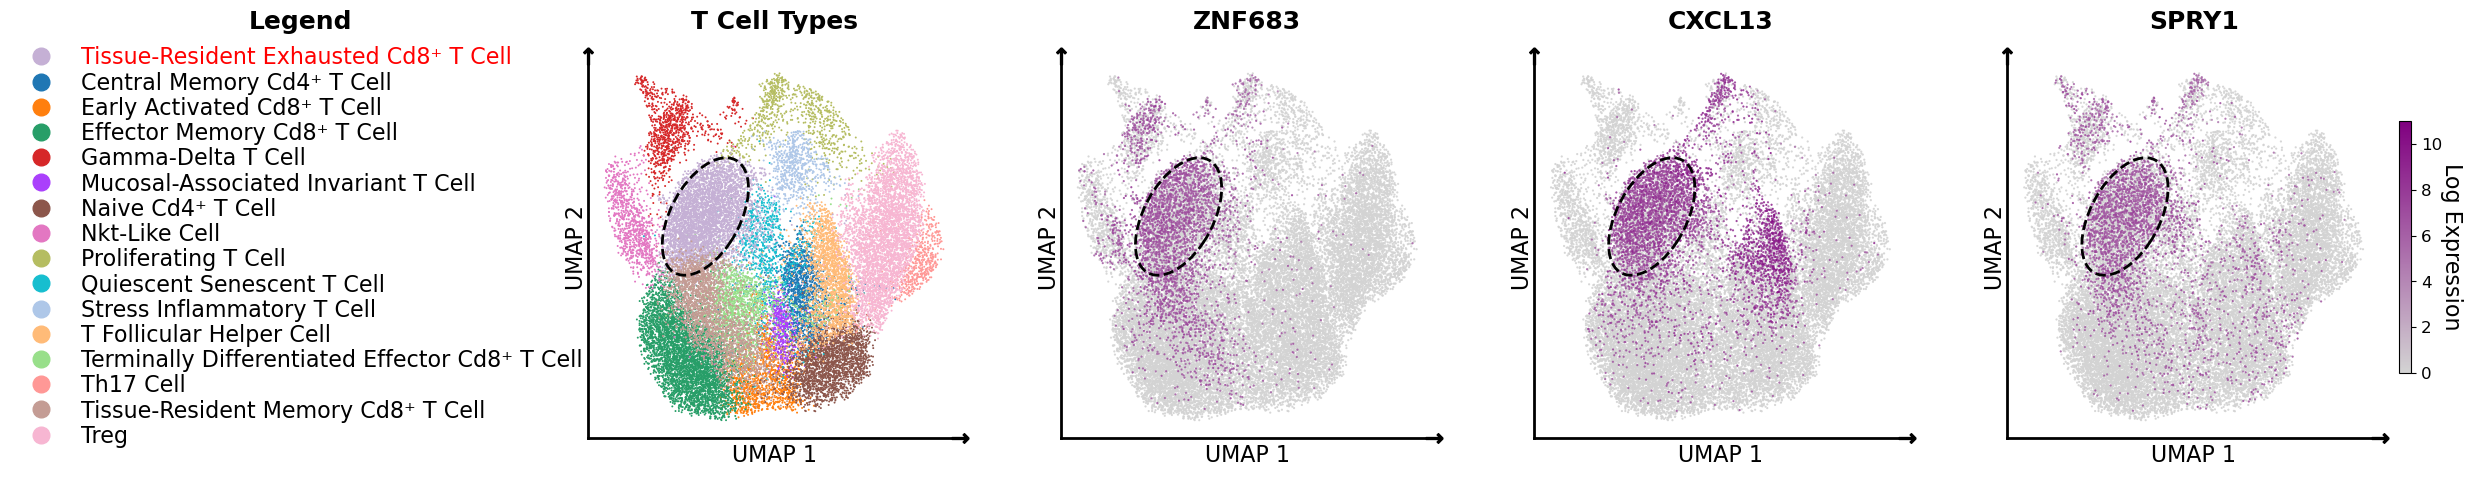

In [1]:
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Ellipse
import matplotlib as mpl
import numpy as np

# ================= 1. Free Configuration =================
highlight_t_cells = ["Tissue-Resident Exhausted Cd8⁺ T Cell"]  # T cell subtypes to highlight
fade_alpha = 1.0  # [Free config] Alpha for non-highlighted cells (0.0 ~ 1.0)

colors = ["lightgrey", "purple"]
cmap_grey_purple = LinearSegmentedColormap.from_list("grey_purple", colors, N=256)
plt.rcParams.update({'font.size': 12})

adata_T = sc.read("../h5ad/adata_T.h5ad")
sc.pp.normalize_total(adata_T, target_sum=1e6)
sc.pp.log1p(adata_T)


genes = ["ZNF683", "CXCL13", "SPRY1"]
vmin = 0
vmax = max(adata_T[:, g].X.max() if hasattr(adata_T[:, g].X, 'max') else adata_T[:, g].X.toarray().max() for g in genes)

# Ellipse parameter configuration
ellipse_center_x = -4.0
ellipse_center_y = 7.0
ellipse_width = 17.0
ellipse_height = 10.0
ellipse_angle = 50
# ================================================

# 2. Create a 1x5 canvas
fig, axes = plt.subplots(1, 5, figsize=(28, 5)) 

# --- Manually draw the cell type legend on the leftmost axes[0] ---
axes[0].set_title("Legend", fontsize=18, fontweight='bold')


# Extract original categories and colors
cats = list(adata_T.obs["celltype"].cat.categories)
colors_celltype = list(adata_T.uns["celltype_colors"])

# Reorder: move types in highlight_t_cells to the front, keep the rest in original relative order
ordered_cats = [c for c in highlight_t_cells if c in cats] + \
               [c for c in cats if c not in highlight_t_cells]

# Draw legend items (colors keep the original mapping)
for cat in ordered_cats:
    idx = cats.index(cat)
    color = colors_celltype[idx]
    axes[0].plot([], [], marker='o', color=color, linestyle='None', markersize=8, label=cat)

# Generate the legend
legend = axes[0].legend(
    loc='center', 
    fontsize=16, 
    frameon=False, 
    ncol=1,
    labelspacing=0.1,
    markerscale=1.5
)

# Set text colors: red for highlighted cells, black for the rest
for text, cat in zip(legend.get_texts(), ordered_cats):
    if cat in highlight_t_cells:
        text.set_color('red')
    else:
        text.set_color('black')

axes[0].axis('off')  # Hide the axes of the legend subplot

# --- Draw the UMAP plot on axes[1] using Matplotlib's low-level API ---
# Get UMAP coordinates
umap_coords = adata_T.obsm["X_umap"]
cell_types = adata_T.obs["celltype"]

# Build the original color mapping dictionary
color_map = dict(zip(cats, colors_celltype))

# Iterate over each cell type for layered drawing
for cat in cats:
    mask = (cell_types == cat)
    x = umap_coords[mask, 0]
    y = umap_coords[mask, 1]
    
    # Alpha is 1.0 for highlighted cells; use fade_alpha for non-highlighted cells
    current_alpha = 1.0 if cat in highlight_t_cells else fade_alpha
    
    axes[1].scatter(
        x, y, 
        c=color_map[cat], 
        s=2,            # Corresponds to scanpy's size=7
        alpha=current_alpha, 
        edgecolors='none',
        rasterized=True # Prevent excessively large files when exporting to PDF/SVG
    )

axes[1].set_title("T Cell Types", fontsize=18, fontweight='bold')
axes[1].set_frame_on(False)

# Add a dashed ellipse to the UMAP plot
ellipse_1 = Ellipse(
    xy=(ellipse_center_x, ellipse_center_y), 
    width=ellipse_width, 
    height=ellipse_height, 
    angle=ellipse_angle,
    fill=False, linestyle='--', linewidth=2.0, edgecolor='black'
)
axes[1].add_patch(ellipse_1)

# --- Draw the 3 gene expression plots on the right (axes[2], axes[3], axes[4]) ---
for i, gene in enumerate(genes):
    sc.pl.umap(
        adata_T, 
        color=gene, 
        ax=axes[i+2], 
        show=False,
        size=10,
        alpha=0.9,
        cmap=cmap_grey_purple, 
        frameon=False,
        colorbar_loc=None, 
        vmin=vmin, 
        vmax=vmax,
        title=gene,
        legend_loc=None,
    )

    axes[i+2].set_title(
        gene, 
        fontsize=18, 
        fontweight='bold', 
        color='black'
    )
    
    ellipse = Ellipse(
        xy=(ellipse_center_x, ellipse_center_y), 
        width=ellipse_width, 
        height=ellipse_height, 
        angle=ellipse_angle,
        fill=False, linestyle='--', linewidth=2.0, edgecolor='black'
    )
    axes[i+2].add_patch(ellipse)

# 3. Uniformly beautify the axes of UMAP subplots (skip the legend subplot axes[0])
umap_axes = [axes[1]] + list(axes[2:])
for ax in umap_axes:
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.plot([xmin, xmax], [ymin, ymin], color='black', linewidth=2.0, transform=ax.transData, clip_on=False)
    ax.plot([xmin, xmin], [ymin, ymax], color='black', linewidth=2.0, transform=ax.transData, clip_on=False)

    ax.plot(xmax, ymin, marker=r'$\rightarrow$', markersize=12, color='black', transform=ax.transData, clip_on=False)
    ax.plot(xmin, ymax, marker=r'$\uparrow$', markersize=12, color='black', transform=ax.transData, clip_on=False)

    x_mid = (xmin + xmax) / 2
    y_mid = (ymin + ymax) / 2
    ax.text(x_mid, ymin-0.8, "UMAP 1", transform=ax.transData, fontsize=16,
            verticalalignment='top', horizontalalignment='center', clip_on=False)
    ax.text(xmin, y_mid, "UMAP 2", transform=ax.transData, fontsize=16,
            rotation=90, verticalalignment='center', horizontalalignment='right', clip_on=False)
    ax.set_xticks([])
    ax.set_yticks([])

# 5. Manually add a shared colorbar
plt.subplots_adjust(wspace=-0.1) 
plt.tight_layout()
norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
sm = mpl.cm.ScalarMappable(cmap=cmap_grey_purple, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, shrink=0.6, aspect=20, pad=0.)
cbar.set_label('Log Expression', rotation=270, labelpad=15, fontsize=16)

plt.show()